Grid index loaded
CSV: /home/users/jianxing/New_final/ACI_gridpoint_index.csv
Total selected gridpoints: 404
  Original cluster 1 -> Cluster 1: 120 gridpoints
  Original cluster 5 -> Cluster 2: 170 gridpoints
  Original cluster 7 -> Cluster 3: 114 gridpoints

Optimal indices loaded
Index file: /home/users/jianxing/copy/optimal_constraint_13th_variable_indices_from_1M.dat
Number of optimal samples: 5000
Min index: 405
Max index: 999775

Processing forcing uncertainty

--- c1 -> Cluster 1 ---
Gridpoints in CSV: 120
  jan: optimal cluster-mean uncertainty = 4.683596, unconstrained cluster-mean uncertainty = 7.323121, forcing n=120, missing=0
  feb: optimal cluster-mean uncertainty = 4.948343, unconstrained cluster-mean uncertainty = 7.911321, forcing n=120, missing=0
  mar: optimal cluster-mean uncertainty = 6.451011, unconstrained cluster-mean uncertainty = 11.044305, forcing n=120, missing=0
  apr: optimal cluster-mean uncertainty = 5.920620, unconstrained cluster-mean uncertainty = 11.

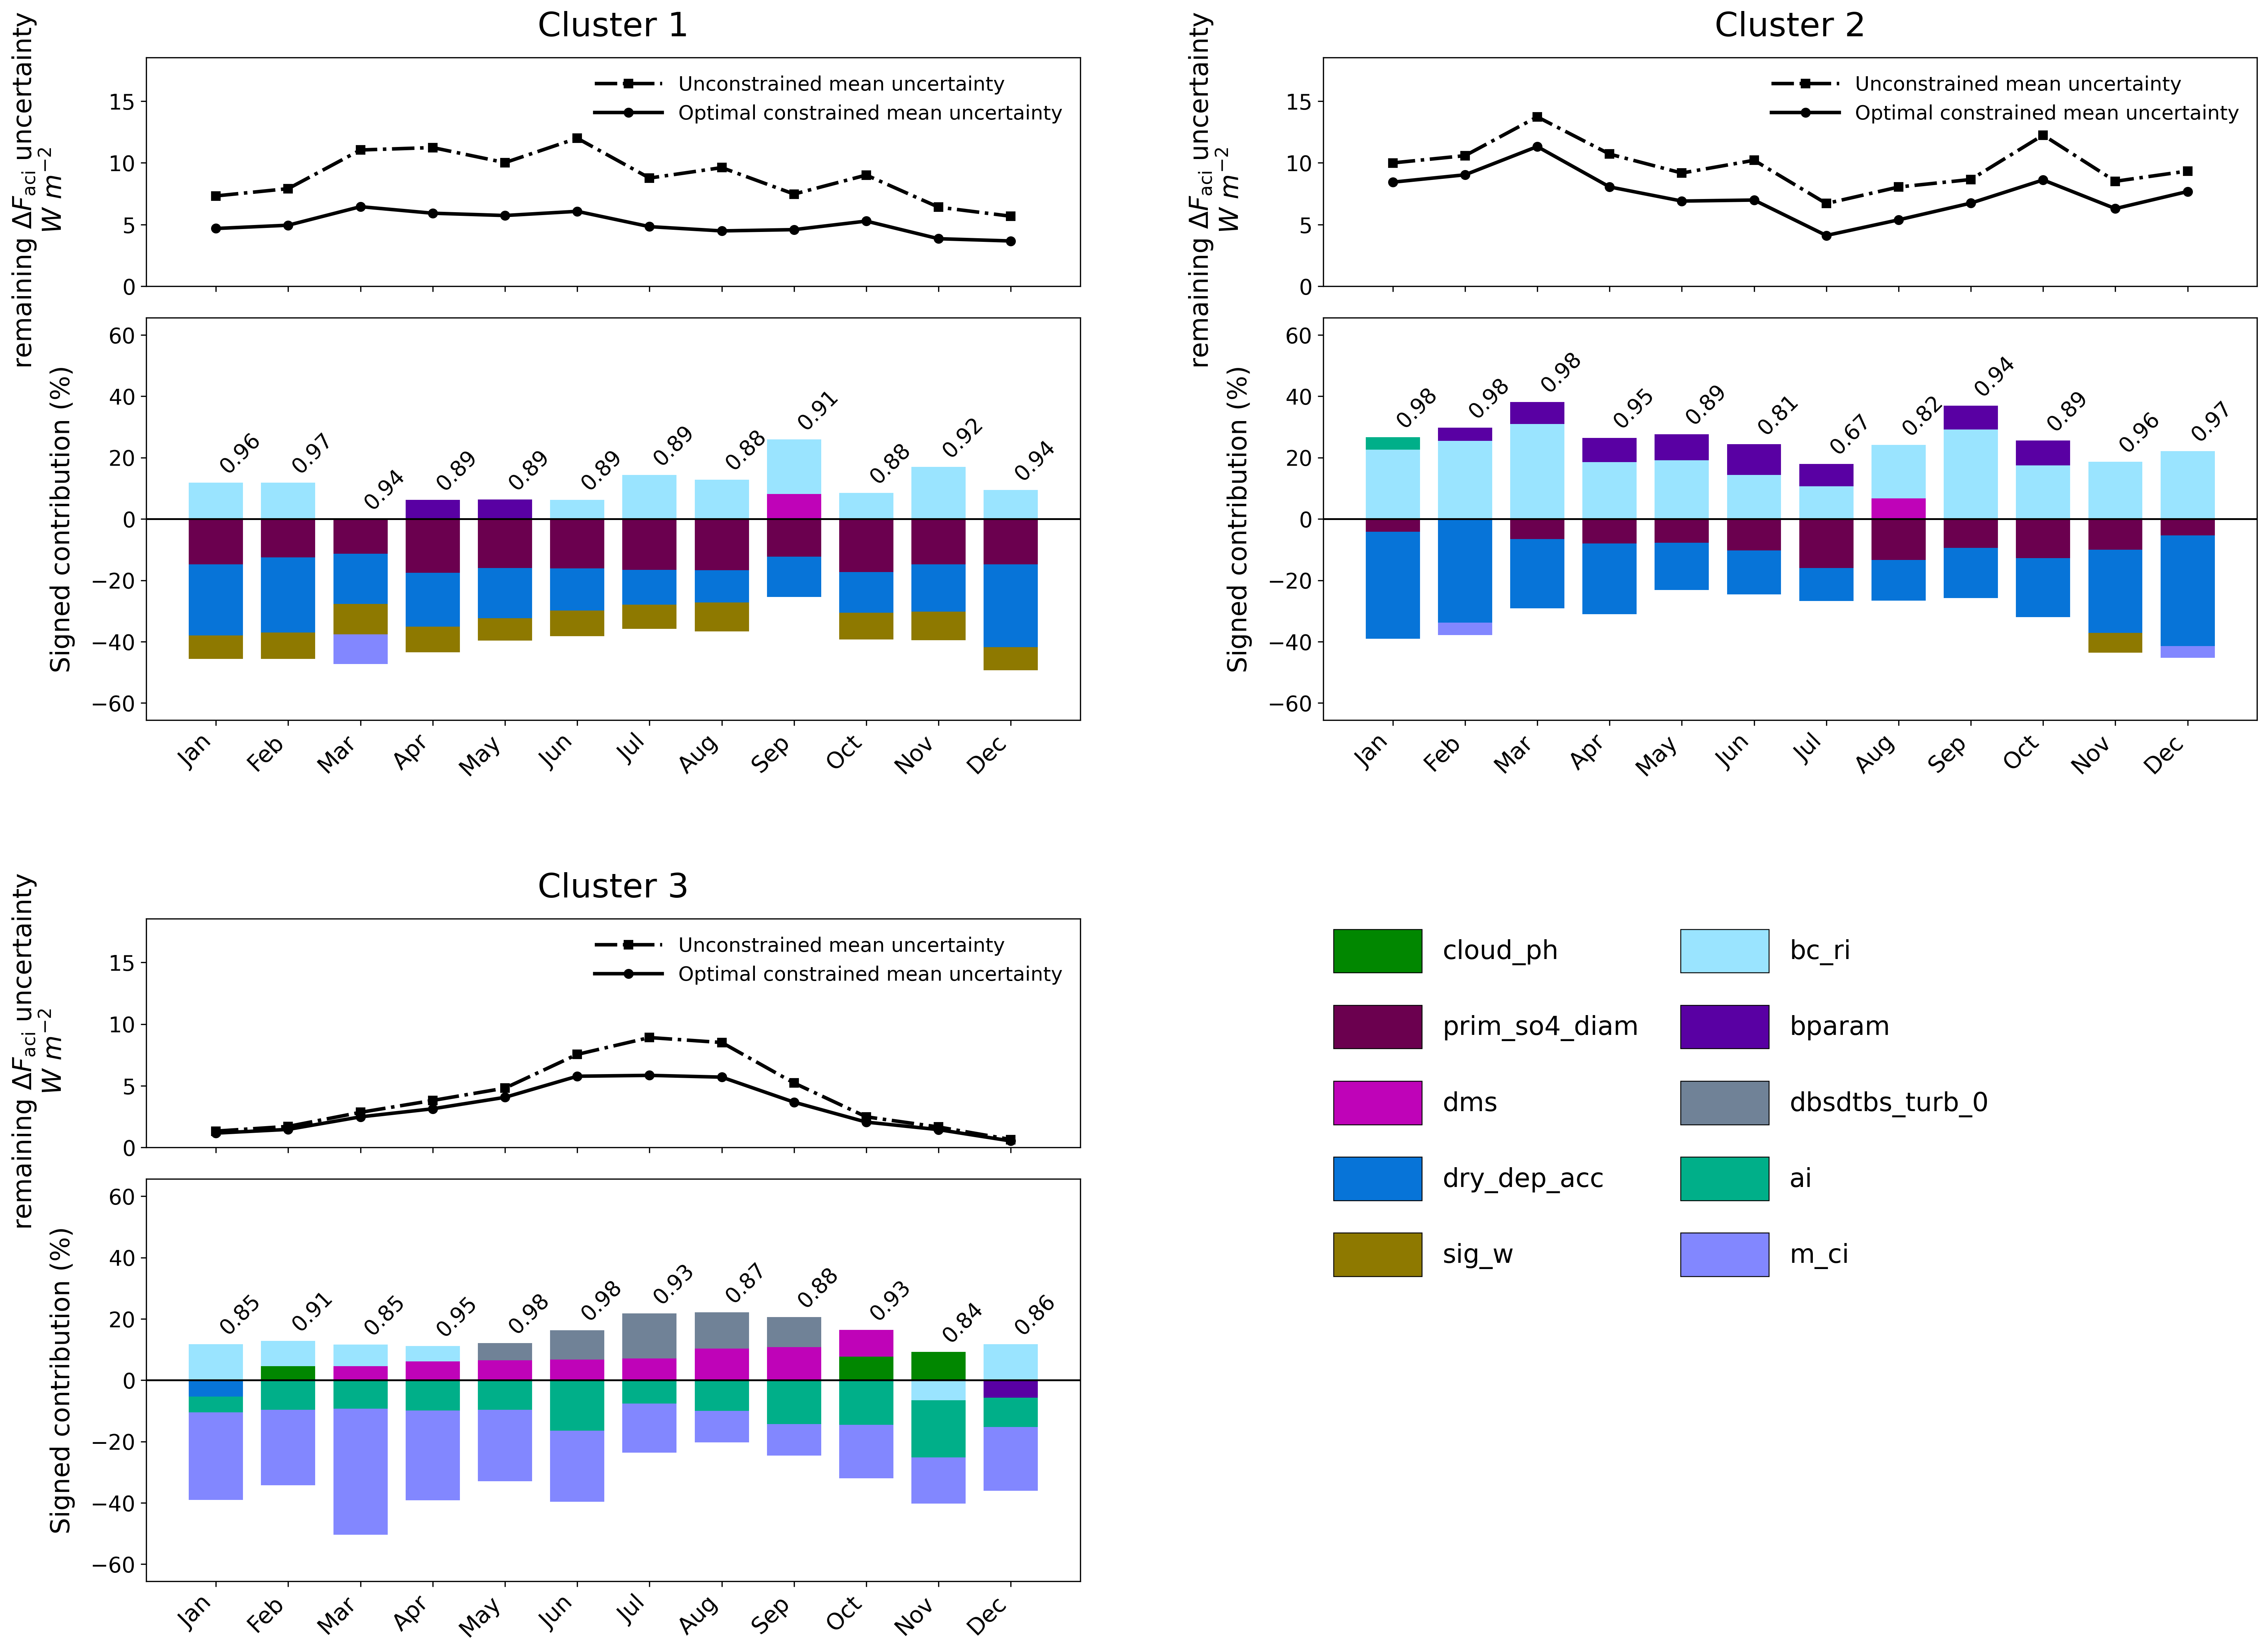

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
import colorcet as cc

# ==========================================
# CONFIGURATION
# ==========================================

# ---- GAM summary file ----
infile = "/gws/ssde/j25a/acure/jianxing/aci/GAM_values/ACI/summary/ACI_GAM_relative_importance_optimal_constrained.csv"

# ---- Gridpoint index table generated from folders ----
grid_index_file = "/home/users/jianxing/New_final/ACI_gridpoint_index.csv"

# ---- GPE emulated forcing output path ----
forcing_base_path = "/gws/ssde/j25a/acure/jianxing/aci/emulation/data_post_emulation/"

# ---- Optimal index file candidates ----
optimal_indices_candidates = [
    "/home/users/jianxing/copy/optimal_constraint_13th_variable_indices_from_1M.dat"
]

# ---- Basic settings ----
var_name = "ACI"
sample_size_full = 1000000

# Remaining uncertainty:
# First calculate the spatial mean across all grid boxes in each cluster for every model variant,
# then calculate p95 - p5 separately for optimal constrained and unconstrained samples.
ci_lower = 5
ci_upper = 95

target_clusters = ["c1", "c5", "c7"]
target_cluster_ids = [1, 5, 7]

# Display original clusters 1/5/7 as Cluster 1/2/3.
cluster_title_map = {
    "c1": "Cluster 1",
    "c5": "Cluster 2",
    "c7": "Cluster 3"
}

cluster_id_to_code = {
    1: "c1",
    5: "c5",
    7: "c7"
}

# Plot January through December only; exclude the annual mean (ANN).
months = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Retain ANN in the GAM parameter-contribution calculation,
# but use it only to define reference parameters for similarity, not for plotting.
months_for_calculation = months + ["ann"]

# For each cluster-month, plot only the four parameters
# with the largest cluster_month_pct values.
top_n = 4

# Parameters with ANN contribution strictly above this threshold
# are used to calculate CCC similarity between each month and ANN.
ann_contribution_threshold = 2.0

parameter_names_subset = [
    "bl_nuc",
    "ait_width",
    "cloud_ph",
    "carb_ff_diam",
    "carb_bb_diam",
    "carb_res_diam",
    "prim_so4_diam",
    "sea_spray",
    "anth_so2_chi",
    "anth_so2_asi",
    "anth_so2_eur",
    "anth_so2_nam",
    "anth_so2_r",
    "volc_so2",
    "bvoc_soa",
    "dms",
    "prim_moc",
    "dry_dep_ait",
    "dry_dep_acc",
    "dry_dep_so2",
    "kappa_oc",
    "sig_w",
    "rain_frac",
    "cloud_ice_thresh",
    "conv_plume_scav",
    "bc_ri",
    "oxidants_oh",
    "oxidants_o3",
    "bparam",
    "two_d_fsd_factor",
    "c_r_correl",
    "autoconv_exp_lwp",
    "autoconv_exp_nd",
    "dbsdtbs_turb_0",
    "ai",
    "m_ci",
    "a_ent_1_rp"
]

color_list = cc.glasbey[:len(parameter_names_subset)]

param_color_dict = dict(
    zip(
        parameter_names_subset,
        color_list
    )
)

PRINT_MISSING_WARNINGS = False


# ==========================================
# HELPER FUNCTIONS
# ==========================================

def resolve_existing_path(candidate_list):

    for path in candidate_list:

        if os.path.exists(path):
            return path

    return None


def load_optimal_indices(index_file):
    """
    Use optimal indices exactly as in the reference program:

        optimal_indices_decimal = np.loadtxt(...)
        optimal_indices = [int(i) for i in optimal_indices_decimal]

    Do not subtract 1 from indices.
    """

    optimal_indices_decimal = np.loadtxt(
        index_file
    )

    optimal_indices = [
        int(i)
        for i in optimal_indices_decimal
    ]

    return optimal_indices


def clean_cluster_value(x):

    return int(
        float(x)
    )


def build_region_tag(row):
    """
    Build the region tag used in filenames from the grid-index CSV:

        cluster=1,
        lat_dir=lat_31.88,
        lon_dir=lon_115.31

        -> c1_lat_31.88_lon_115.31
    """

    cluster_id = clean_cluster_value(
        row["cluster"]
    )

    lat_dir = str(
        row["lat_dir"]
    )

    lon_dir = str(
        row["lon_dir"]
    )

    return (
        f"c{cluster_id}_"
        f"{lat_dir}_"
        f"{lon_dir}"
    )


def get_forcing_file(
    month,
    region_tag
):
    """
    GPE forcing filename:

        emulated_mean_values_{month}_ACI_
        {region_tag}_1000000_w_o_carb.dat
    """

    filename = (
        f"emulated_mean_values_{month}_{var_name}_"
        f"{region_tag}_{sample_size_full}_w_o_carb.dat"
    )

    return os.path.join(
        forcing_base_path,
        filename
    )


def compute_cluster_month_remaining_uncertainty(
    cluster_df,
    month,
    optimal_indices
):
    """
    For one cluster and one month:

    1. Read all 1M emulated forcing values for each grid box in the cluster.

    2. For each model variant, calculate the spatial mean forcing
       over all available grid boxes within the cluster.

    3. Obtain 1M cluster-mean forcing values.

    4. Calculate unconstrained uncertainty using all 1M
       cluster-mean forcing values:

           p95 - p5

    5. Select OP samples with optimal_indices, using their
       cluster-mean forcing values, and calculate:

           p95 - p5

    6. Return summary statistics for this cluster-month.
    """

    cluster_forcing_sum = np.zeros(
        sample_size_full,
        dtype=float
    )

    n_grid_used = 0

    n_missing = 0


    for _, row in cluster_df.iterrows():

        region_tag = row[
            "region_tag"
        ]

        forcing_file = get_forcing_file(
            month,
            region_tag
        )


        if not os.path.exists(
            forcing_file
        ):

            n_missing += 1

            if PRINT_MISSING_WARNINGS:

                print(
                    f"Missing forcing file: "
                    f"{forcing_file}"
                )

            continue


        try:

            var_full = np.loadtxt(
                forcing_file
            )

            if len(var_full) != sample_size_full:

                raise ValueError(
                    f"Sample size mismatch: "
                    f"{forcing_file}. "
                    f"Expected {sample_size_full}, "
                    f"got {len(var_full)}"
                )

        except Exception as e:

            n_missing += 1

            if PRINT_MISSING_WARNINGS:

                print(
                    f"Failed to process forcing file: "
                    f"{forcing_file} | {e}"
                )

            continue


        cluster_forcing_sum += var_full

        n_grid_used += 1


    if n_grid_used == 0:

        return None


    cluster_mean_forcing_full = (
        cluster_forcing_sum
        / n_grid_used
    )


    # ==========================================
    # Unconstrained 1M cluster-mean uncertainty
    # ==========================================

    unconstrained_q_low, unconstrained_q_high = (
        np.percentile(
            cluster_mean_forcing_full,
            [
                ci_lower,
                ci_upper
            ]
        )
    )


    unconstrained_uncertainty = (
        unconstrained_q_high
        - unconstrained_q_low
    )


    # ==========================================
    # Optimal constrained cluster-mean uncertainty
    # ==========================================

    # Follow the reference program exactly:
    # Do not subtract 1 from indices.
    cluster_mean_forcing_optimal = (
        cluster_mean_forcing_full[
            optimal_indices
        ]
    )


    optimal_q_low, optimal_q_high = (
        np.percentile(
            cluster_mean_forcing_optimal,
            [
                ci_lower,
                ci_upper
            ]
        )
    )


    remaining_uncertainty = (
        optimal_q_high
        - optimal_q_low
    )


    return {
        "remaining_uncertainty":
            remaining_uncertainty,

        "unconstrained_uncertainty":
            unconstrained_uncertainty,

        "n_grid_used":
            n_grid_used,

        "n_missing":
            n_missing
    }


def concordance_correlation_coefficient(
    x,
    y
):
    """
    Calculate Lin's concordance correlation
    coefficient (CCC).

    Compare:

        monthly signed_cluster_month_pct over parameters
        with ANN contribution > 2%,
        signed_cluster_month_pct

    with:

        ANN signed_cluster_month_pct over the same parameters.
        signed_cluster_month_pct
    """

    x = np.asarray(
        x,
        dtype=float
    )

    y = np.asarray(
        y,
        dtype=float
    )

    valid = (
        np.isfinite(x)
        & np.isfinite(y)
    )

    x = x[
        valid
    ]

    y = y[
        valid
    ]


    if len(x) < 2:

        return np.nan


    mean_x = np.mean(
        x
    )

    mean_y = np.mean(
        y
    )

    var_x = np.mean(
        (
            x
            - mean_x
        ) ** 2
    )

    var_y = np.mean(
        (
            y
            - mean_y
        ) ** 2
    )

    covariance = np.mean(
        (
            x
            - mean_x
        )
        * (
            y
            - mean_y
        )
    )

    denominator = (
        var_x
        + var_y
        + (
            mean_x
            - mean_y
        ) ** 2
    )


    if np.isclose(
        denominator,
        0.0
    ):

        if np.allclose(
            x,
            y
        ):

            return 1.0

        return np.nan


    ccc = (
        2.0
        * covariance
        / denominator
    )

    return float(
        ccc
    )


# ==========================================
# READ GRID INDEX AND OPTIMAL INDICES
# ==========================================

if not os.path.exists(
    grid_index_file
):

    raise FileNotFoundError(
        f"Grid index CSV not found: "
        f"{grid_index_file}"
    )


grid_index = pd.read_csv(
    grid_index_file
)


required_grid_cols = [
    "idx",
    "cluster",
    "lat_dir",
    "lon_dir"
]


missing_grid_cols = [
    c
    for c in required_grid_cols
    if c not in grid_index.columns
]


if missing_grid_cols:

    raise ValueError(
        f"Missing required columns in "
        f"grid index CSV: "
        f"{missing_grid_cols}"
    )


grid_index[
    "cluster_id"
] = (
    grid_index[
        "cluster"
    ]
    .apply(
        clean_cluster_value
    )
)


grid_index[
    "cluster_code"
] = (
    grid_index[
        "cluster_id"
    ]
    .map(
        cluster_id_to_code
    )
)


grid_index[
    "region_tag"
] = grid_index.apply(
    build_region_tag,
    axis=1
)


grid_index = grid_index[
    grid_index[
        "cluster_id"
    ].isin(
        target_cluster_ids
    )
].copy()


if grid_index.empty:

    raise RuntimeError(
        "No valid gridpoints found "
        "for cluster 1/5/7."
    )


if (
    "lat" in grid_index.columns
    and "lon" in grid_index.columns
):

    grid_index = (
        grid_index
        .sort_values(
            [
                "cluster_id",
                "lat",
                "lon"
            ]
        )
        .reset_index(
            drop=True
        )
    )

else:

    grid_index = (
        grid_index
        .sort_values(
            [
                "cluster_id",
                "lat_dir",
                "lon_dir"
            ]
        )
        .reset_index(
            drop=True
        )
    )


print(
    "Grid index loaded"
)

print(
    "CSV:",
    grid_index_file
)

print(
    "Total selected gridpoints:",
    len(grid_index)
)


for cid in target_cluster_ids:

    cluster_code = (
        cluster_id_to_code[
            cid
        ]
    )

    print(
        f"  Original cluster {cid} -> "
        f"{cluster_title_map[cluster_code]}: "
        f"{(
            grid_index['cluster_id']
            == cid
        ).sum()} "
        f"gridpoints"
    )


optimal_indices_file = (
    resolve_existing_path(
        optimal_indices_candidates
    )
)


if optimal_indices_file is None:

    raise FileNotFoundError(
        "Could not find optimal index file. "
        "Tried:\n"
        + "\n".join(
            optimal_indices_candidates
        )
    )


optimal_indices = load_optimal_indices(
    optimal_indices_file
)


n_optimal = len(
    optimal_indices
)


print(
    "\nOptimal indices loaded"
)

print(
    "Index file:",
    optimal_indices_file
)

print(
    "Number of optimal samples:",
    n_optimal
)

print(
    "Min index:",
    min(
        optimal_indices
    )
)

print(
    "Max index:",
    max(
        optimal_indices
    )
)


if max(
    optimal_indices
) >= sample_size_full:

    raise ValueError(
        f"Max optimal index "
        f"{max(optimal_indices)} "
        f"exceeds sample size "
        f"{sample_size_full}. "
        "This program follows your "
        "reference code and does not "
        "subtract 1."
    )


# ==========================================
# COMPUTE CLUSTER MONTHLY REMAINING UNCERTAINTY
# ==========================================

remaining_uncertainty_all = {
    cluster: {}
    for cluster in target_clusters
}


print(
    "\n=============================="
)

print(
    "Processing forcing uncertainty"
)

print(
    "=============================="
)


for cluster_code in target_clusters:

    cluster_df = grid_index[
        grid_index[
            "cluster_code"
        ]
        == cluster_code
    ].copy()


    print(
        f"\n--- {cluster_code} -> "
        f"{cluster_title_map[cluster_code]} ---"
    )

    print(
        f"Gridpoints in CSV: "
        f"{len(cluster_df)}"
    )


    for month in months:

        result = (
            compute_cluster_month_remaining_uncertainty(
                cluster_df=cluster_df,
                month=month,
                optimal_indices=optimal_indices
            )
        )


        remaining_uncertainty_all[
            cluster_code
        ][month] = result


        if result is None:

            n_used = 0

            n_missing = len(
                cluster_df
            )

            mean_value = np.nan

            unconstrained_mean_value = np.nan


        else:

            n_used = result[
                "n_grid_used"
            ]

            n_missing = result[
                "n_missing"
            ]

            mean_value = result[
                "remaining_uncertainty"
            ]

            unconstrained_mean_value = result[
                "unconstrained_uncertainty"
            ]


        print(
            f"  {month}: "
            f"optimal cluster-mean uncertainty = "
            f"{mean_value:.6f}, "
            f"unconstrained cluster-mean uncertainty = "
            f"{unconstrained_mean_value:.6f}, "
            f"forcing n={n_used}, "
            f"missing={n_missing}"
        )


# ==========================================
# READ GAM SUMMARY DATA
# ==========================================

if not os.path.exists(
    infile
):

    raise FileNotFoundError(
        f"Input file not found: "
        f"{infile}"
    )


df = pd.read_csv(
    infile
)


required_cols = [
    "month",
    "cluster",
    "param",
    "variance_pct",
    "gradient_sign"
]


missing_cols = [
    c
    for c in required_cols
    if c not in df.columns
]


if missing_cols:

    raise ValueError(
        f"Missing required columns "
        f"in input file: "
        f"{missing_cols}"
    )


# ==========================================
# FILTER DATA
# ==========================================

df_use = df[
    (
        df["cluster"].isin(
            target_clusters
        )
    )
    & (
        df["month"].isin(
            months_for_calculation
        )
    )
    & (
        df["param"].isin(
            parameter_names_subset
        )
    )
].copy()


if df_use.empty:

    raise ValueError(
        "No valid data found after "
        "filtering cluster/month/param."
    )


df_use = df_use.dropna(
    subset=[
        "variance_pct",
        "gradient_sign"
    ]
)


# ==========================================
# RECOVER SIGNED RESPONSE
# ==========================================

df_use[
    "signed_response"
] = (
    df_use[
        "variance_pct"
    ]
    * df_use[
        "gradient_sign"
    ]
)


grouped = (
    df_use
    .groupby(
        [
            "cluster",
            "month",
            "param"
        ],
        as_index=False
    )[
        "signed_response"
    ]
    .mean()
    .rename(
        columns={
            "signed_response":
            "cluster_month_param_mean_signed_response"
        }
    )
)


# Complete all cluster x month x parameter combinations.
# Include January through December and ANN.
full_index = pd.MultiIndex.from_product(
    [
        target_clusters,
        months_for_calculation,
        parameter_names_subset
    ],
    names=[
        "cluster",
        "month",
        "param"
    ]
)


grouped = (
    grouped
    .set_index(
        [
            "cluster",
            "month",
            "param"
        ]
    )
    .reindex(
        full_index
    )
    .reset_index()
)


grouped[
    "cluster_month_param_mean_signed_response"
] = grouped[
    "cluster_month_param_mean_signed_response"
].fillna(
    0.0
)


# Calculate the mean first, then take its absolute value.
grouped[
    "abs_after_sign_mean"
] = grouped[
    "cluster_month_param_mean_signed_response"
].abs()


# Normalize contributions to 100% within each cluster-month.
month_totals = grouped.groupby(
    [
        "cluster",
        "month"
    ]
)[
    "abs_after_sign_mean"
].transform(
    "sum"
)


grouped[
    "cluster_month_pct"
] = np.where(
    month_totals > 0,
    (
        100.0
        * grouped[
            "abs_after_sign_mean"
        ]
        / month_totals
    ),
    np.nan
)


# Apply the response sign to the percentages.
grouped[
    "direction_sign"
] = np.sign(
    grouped[
        "cluster_month_param_mean_signed_response"
    ]
)


grouped[
    "signed_cluster_month_pct"
] = (
    grouped[
        "cluster_month_pct"
    ]
    * grouped[
        "direction_sign"
    ]
)


# ==========================================
# CALCULATE MONTHLY SIMILARITY TO ANN
# ==========================================

ann_top5_parameters = {
    cluster: []
    for cluster in target_clusters
}


monthly_ann_similarity = {
    cluster: {}
    for cluster in target_clusters
}


print(
    "\n"
    + "=" * 100
)

print(
    "ANN parameters with contribution "
    f"> {ann_contribution_threshold}% "
    "and monthly CCC similarity"
)

print(
    "=" * 100
)


for cluster in target_clusters:

    cluster_data = grouped[
        grouped[
            "cluster"
        ]
        == cluster
    ].copy()


    ann_data = cluster_data[
        cluster_data[
            "month"
        ]
        == "ann"
    ].copy()


    ann_data = ann_data.sort_values(
        "cluster_month_pct",
        ascending=False
    )


    # Retain all parameters with ANN contribution strictly above 2%
    # for the similarity calculation.
    ann_top5 = (
        ann_data[
            ann_data[
                "cluster_month_pct"
            ]
            > ann_contribution_threshold
        ][
            "param"
        ]
        .tolist()
    )


    if len(
        ann_top5
    ) == 0:

        raise RuntimeError(
            f"{cluster}: no ANN parameter "
            f"has cluster_month_pct > "
            f"{ann_contribution_threshold}%."
        )


    ann_top5_parameters[
        cluster
    ] = ann_top5


    ann_series = (
        ann_data
        .set_index(
            "param"
        )[
            "signed_cluster_month_pct"
        ]
        .reindex(
            ann_top5
        )
    )


    ann_vector = (
        ann_series
        .values
        .astype(
            float
        )
    )


    print(
        f"\n{cluster} -> "
        f"{cluster_title_map[cluster]}"
    )

    print(
        f"Number of ANN parameters with "
        f"contribution > "
        f"{ann_contribution_threshold}%: "
        f"{len(ann_top5)}"
    )

    print(
        "ANN reference parameters:",
        ", ".join(
            ann_top5
        )
    )

    print(
        "ANN signed contribution vector:",
        np.array2string(
            ann_vector,
            precision=4,
            separator=", "
        )
    )


    for month in months:

        month_data = cluster_data[
            cluster_data[
                "month"
            ]
            == month
        ].copy()


        month_series = (
            month_data
            .set_index(
                "param"
            )[
                "signed_cluster_month_pct"
            ]
            .reindex(
                ann_top5
            )
        )


        month_vector = (
            month_series
            .values
            .astype(
                float
            )
        )


        similarity = (
            concordance_correlation_coefficient(
                month_vector,
                ann_vector
            )
        )


        monthly_ann_similarity[
            cluster
        ][month] = similarity


        print(
            f"  {month}: "
            f"CCC = {similarity:.6f}"
        )


# ==========================================
# KEEP TOP 4 BY cluster_month_pct
# ==========================================

grouped[
    "rank_top5"
] = (
    grouped
    .groupby(
        [
            "cluster",
            "month"
        ]
    )[
        "cluster_month_pct"
    ]
    .rank(
        method="first",
        ascending=False
    )
)


# Exclude ANN from the bar-chart display.
grouped_plot = grouped[
    (
        grouped[
            "month"
        ].isin(
            months
        )
    )
    & (
        grouped[
            "rank_top5"
        ]
        <= top_n
    )
].copy()


# ==========================================
# PRINT CHECK TABLE
# ==========================================

print(
    "\n"
    + "=" * 100
)

print(
    f"Top {top_n} parameters by "
    "cluster_month_pct for each "
    "cluster-month"
)

print(
    "=" * 100
)


print(
    grouped_plot[
        [
            "cluster",
            "month",
            "param",
            "cluster_month_pct",
            "signed_cluster_month_pct"
        ]
    ]
    .sort_values(
        [
            "cluster",
            "month",
            "cluster_month_pct"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .head(
        60
    )
    .to_string(
        index=False
    )
)


# ==========================================
# Y-LIMITS
# ==========================================

# lower stacked bar y-limit
all_positive_stack = []

all_negative_stack = []


for cluster in target_clusters:

    sub = grouped_plot[
        grouped_plot[
            "cluster"
        ]
        == cluster
    ].copy()


    for month in months:

        vals = sub[
            sub[
                "month"
            ]
            == month
        ][
            "signed_cluster_month_pct"
        ].fillna(
            0.0
        ).values


        pos_sum = vals[
            vals > 0
        ].sum()


        neg_sum = vals[
            vals < 0
        ].sum()


        all_positive_stack.append(
            pos_sum
        )


        all_negative_stack.append(
            abs(
                neg_sum
            )
        )


if (
    len(
        all_positive_stack
    ) == 0
    and len(
        all_negative_stack
    ) == 0
):

    bar_ylim = 5.0


else:

    ymax = max(
        (
            max(
                all_positive_stack
            )
            if len(
                all_positive_stack
            ) > 0
            else 0
        ),
        (
            max(
                all_negative_stack
            )
            if len(
                all_negative_stack
            ) > 0
            else 0
        )
    )


    bar_ylim = (
        1.30
        * ymax
        if ymax > 0
        else 5.0
    )


    bar_ylim = max(
        bar_ylim,
        5.0
    )


# ==========================================
# Upper remaining uncertainty y-limit
# ==========================================

all_unc_values = []


for cluster in target_clusters:

    for month in months:

        result = remaining_uncertainty_all[
            cluster
        ].get(
            month
        )


        if result is not None:

            optimal_mean_value = result[
                "remaining_uncertainty"
            ]

            unconstrained_mean_value = result[
                "unconstrained_uncertainty"
            ]


            if np.isfinite(
                optimal_mean_value
            ):

                all_unc_values.append(
                    optimal_mean_value
                )


            if np.isfinite(
                unconstrained_mean_value
            ):

                all_unc_values.append(
                    unconstrained_mean_value
                )


if len(
    all_unc_values
) == 0:

    unc_ylim = None


else:

    unc_ylim = (
        1.35
        * max(
            all_unc_values
        )
    )


# ==========================================
# PLOT FUNCTIONS
# ==========================================

def plot_cluster_panel(
    fig,
    subspec,
    cluster
):

    inner = (
        gridspec.GridSpecFromSubplotSpec(
            2,
            1,
            subplot_spec=subspec,
            height_ratios=[
                1.45,
                2.55
            ],
            hspace=0.10
        )
    )


    ax_top = fig.add_subplot(
        inner[
            0
        ]
    )


    ax_bar = fig.add_subplot(
        inner[
            1
        ],
        sharex=ax_top
    )


    x = np.arange(
        len(
            months
        )
    )


    width = 0.75


    # ==========================================
    # Upper plot: monthly uncertainty
    # ==========================================

    mean_values = []

    unconstrained_mean_values = []


    for month in months:

        result = remaining_uncertainty_all[
            cluster
        ].get(
            month
        )


        if result is None:

            mean_values.append(
                np.nan
            )

            unconstrained_mean_values.append(
                np.nan
            )


        else:

            mean_values.append(
                result[
                    "remaining_uncertainty"
                ]
            )

            unconstrained_mean_values.append(
                result[
                    "unconstrained_uncertainty"
                ]
            )


    mean_values = np.asarray(
        mean_values,
        dtype=float
    )


    unconstrained_mean_values = np.asarray(
        unconstrained_mean_values,
        dtype=float
    )


    # Unconstrained 1M
    ax_top.plot(
        x,
        unconstrained_mean_values,
        color="black",
        linewidth=2.3,
        linestyle="-.",
        marker="s",
        markersize=5.5,
        label="Unconstrained mean uncertainty",
        zorder=3
    )


    # Optimal constrained
    ax_top.plot(
        x,
        mean_values,
        color="black",
        linewidth=2.3,
        linestyle="-",
        marker="o",
        markersize=5.5,
        label="Optimal constrained mean uncertainty",
        zorder=4
    )


    ax_top.set_title(
        cluster_title_map[
            cluster
        ],
        fontsize=22,
        pad=14
    )


    # ==========================================
    # ONLY CHANGE HERE:
    # F is italic, "aci" is upright
    # ==========================================

    ax_top.set_ylabel(
        "remaining $\\Delta F_{\\mathrm{aci}}$ uncertainty\n"
        "$W\\ m^{-2}$",
        fontsize=17,
        fontweight="normal",
        labelpad=10
    )
    ax_top.yaxis.set_label_coords(-0.085, 0.42)

    ax_top.tick_params(
        axis="x",
        labelbottom=False,
        labelsize=14
    )


    ax_top.tick_params(
        axis="y",
        labelsize=14
    )


    if unc_ylim is not None:

        ax_top.set_ylim(
            0,
            unc_ylim
        )


    ax_top.legend(
        loc="upper right",
        frameon=False,
        fontsize=13,
        handlelength=3.4
    )


    # ==========================================
    # Lower plot: stacked bars
    # ==========================================

    sub = grouped_plot[
        grouped_plot[
            "cluster"
        ]
        == cluster
    ].copy()


    pos_bottom = np.zeros(
        len(
            months
        )
    )


    neg_bottom = np.zeros(
        len(
            months
        )
    )


    for param in parameter_names_subset:

        sub_param = sub[
            sub[
                "param"
            ]
            == param
        ].copy()


        if sub_param.empty:

            continue


        sub_param = (
            sub_param
            .set_index(
                "month"
            )
            .reindex(
                months
            )
            .reset_index()
        )


        values = sub_param[
            "signed_cluster_month_pct"
        ].fillna(
            0.0
        ).values


        pos_vals = np.where(
            values > 0,
            values,
            0.0
        )


        neg_vals = np.where(
            values < 0,
            values,
            0.0
        )


        if np.any(
            pos_vals != 0
        ):

            ax_bar.bar(
                x,
                pos_vals,
                width=width,
                bottom=pos_bottom,
                color=param_color_dict[
                    param
                ],
                label=param
            )


            pos_bottom += pos_vals


        if np.any(
            neg_vals != 0
        ):

            ax_bar.bar(
                x,
                neg_vals,
                width=width,
                bottom=neg_bottom,
                color=param_color_dict[
                    param
                ]
            )


            neg_bottom += neg_vals


    # ==========================================
    # Add monthly CCC similarity values
    # ==========================================

    text_offset = (
        0.025
        * bar_ylim
    )


    for i, month in enumerate(
        months
    ):

        similarity = monthly_ann_similarity[
            cluster
        ].get(
            month,
            np.nan
        )


        if not np.isfinite(
            similarity
        ):

            continue


        text_y = (
            max(
                pos_bottom[
                    i
                ],
                0.0
            )
            + text_offset
        )


        ax_bar.text(
            x[
                i
            ],
            text_y,
            f"{similarity:.2f}",
            rotation=45,
            ha="left",
            va="bottom",
            fontsize=14,
            fontweight="normal",
            color="black",
            clip_on=False
        )


    ax_bar.axhline(
        0,
        color="black",
        linewidth=1.2
    )


    ax_bar.set_xticks(
        x
    )


    ax_bar.set_xticklabels(
        month_labels,
        rotation=45,
        ha="right",
        fontsize=15
    )


    ax_bar.tick_params(
        axis="y",
        labelsize=14
    )


    ax_bar.set_ylabel(
        "Signed contribution (%)",
        fontsize=17,
        fontweight="normal",
        labelpad=10
    )


    ax_bar.set_ylim(
        -bar_ylim,
        bar_ylim
    )


    return (
        ax_top,
        ax_bar
    )


# ==========================================
# PLOT: 2x2 layout
# ==========================================

fig = plt.figure(
    figsize=(
        24,
        18
    ),
    dpi=300
)


outer = gridspec.GridSpec(
    2,
    2,
    width_ratios=[
        1,
        1
    ],
    height_ratios=[
        1,
        1
    ],
    wspace=0.26,
    hspace=0.30
)


# Left-top: c1 -> Cluster 1
plot_cluster_panel(
    fig,
    outer[
        0,
        0
    ],
    "c1"
)


# Right-top: c5 -> Cluster 2
plot_cluster_panel(
    fig,
    outer[
        0,
        1
    ],
    "c5"
)


# Left-bottom: c7 -> Cluster 3
plot_cluster_panel(
    fig,
    outer[
        1,
        0
    ],
    "c7"
)


# Right-bottom: parameter legend only
ax_leg = fig.add_subplot(
    outer[
        1,
        1
    ]
)


ax_leg.axis(
    "off"
)


# ==========================================
# LEGEND: ONLY PARAMETERS APPEARING
# IN THE MONTHLY TOP-4 BAR CHARTS
# ==========================================

appeared_parameters_set = set(
    grouped_plot[
        "param"
    ]
    .dropna()
    .unique()
)


appeared_parameters = [
    param
    for param in parameter_names_subset
    if param in appeared_parameters_set
]


print(
    "\nParameters appearing in "
    "monthly Top-4 bar charts:"
)

print(
    ", ".join(
        appeared_parameters
    )
)


legend_handles = [
    Patch(
        facecolor=param_color_dict[
            param
        ],
        edgecolor="black",
        linewidth=0.6,
        label=param
    )
    for param in appeared_parameters
]


if len(
    legend_handles
) > 0:

    ax_leg.legend(
        handles=legend_handles,
        loc="upper left",
        bbox_to_anchor=(
            0.00,
            1.00
        ),
        ncol=2,
        frameon=False,
        prop={
            "size": 17,
            "weight": "normal"
        },
        handlelength=3.4,
        handleheight=2.2,
        columnspacing=1.6,
        labelspacing=1.25,
        borderaxespad=0.0
    )


# Do not add an overall figure title.
plt.subplots_adjust(left=0.10)
plt.show()